In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import (
    carregar_noaa_por_tipo,
    identificar_porcoes_ativas,
    processar_ou_carregar_porcao,
    media_por_sink_raio,
    ajustar_lei_potencia,
    plotar_lei_potencia,
    plotar_varredura_r1_a_22km,
)

tipos_noaa = carregar_noaa_por_tipo()
ow_mar = tipos_noaa["Ocean water"]
print(f"Ocean water (0,02-5,0 mm, GEBCO <= 0 no mar): {len(ow_mar)} pontos")


Ocean water (0,02-5,0 mm, GEBCO <= 0 no mar): 14363 pontos


In [2]:
info, arr, label, porcoes_ativas = identificar_porcoes_ativas(ow_mar, max_r_km=50.0)
df_todas = pd.concat(
    [d for d in (processar_ou_carregar_porcao(v, info, arr, label) for v in porcoes_ativas) if len(d) > 0],
    ignore_index=True,
).sort_values("area_km2", ascending=False).reset_index(drop=True)

cum_area = df_todas["area_km2"].cumsum() / df_todas["area_km2"].sum()
cut_idx = int((cum_area <= 0.95).sum()) + 1
df_bacias_ipba = df_todas.iloc[:cut_idx].copy().reset_index(drop=True)
print(f"Bacias totais (h=0): {len(df_todas)} | Recorte IPBA Top 95% Global: {len(df_bacias_ipba)} (area >= {df_bacias_ipba['area_km2'].min():.1f} km2)")


Bacias totais (h=0): 179718 | Recorte IPBA Top 95% Global: 5942 (area >= 645.7 km2)


In [3]:
pareados_por_r = {}
linhas_r = []
for r_km in range(1, 23):
    df_r = media_por_sink_raio(df_bacias_ipba, ow_mar, r_km=r_km)
    pareados_por_r[r_km] = df_r
    st_u = ajustar_lei_potencia(df_r, "urban_population", "mp_mean")
    st_fu = ajustar_lei_potencia(df_r, "urban_population", "flux")
    st_t = ajustar_lei_potencia(df_r, "total_population", "mp_mean")
    st_ft = ajustar_lei_potencia(df_r, "total_population", "flux")
    linhas_r.append({
        "R_km": r_km,
        "N_urb": st_u["N"],
        "beta_urb": st_u["beta"],
        "R2_urb_pct": st_u["r2_pct"],
        "R2_flux_urb_pct": st_fu["r2_pct"],
        "N_tot": st_t["N"],
        "beta_tot": st_t["beta"],
        "R2_tot_pct": st_t["r2_pct"],
        "R2_bins_tot_pct": st_t["r2_bins_pct"],
        "R2_flux_tot_pct": st_ft["r2_pct"],
    })

df_varredura = pd.DataFrame(linhas_r)
print(df_varredura.round(2).to_string(index=False))


 R_km  N_urb  beta_urb  R2_urb_pct  R2_flux_urb_pct  N_tot  beta_tot  R2_tot_pct  R2_bins_tot_pct  R2_flux_tot_pct
    1      0       NaN         NaN              NaN      0       NaN         NaN              NaN              NaN
    2      0       NaN         NaN              NaN      0       NaN         NaN              NaN              NaN
    3      5      0.17       24.95            17.43      6      0.19        8.48              NaN             8.17
    4      9      0.27       21.09            24.95     10      0.32       15.71              NaN            18.37
    5     14      0.65       37.47            37.43     16      0.75       54.09              NaN            49.69
    6     19      0.78       35.19            36.16     24      0.88       34.42              NaN            40.09
    7     23      0.64       17.47            24.31     31      0.86       28.45            24.63            37.04
    8     27      0.43        7.00            14.09     37      0.58       20.10

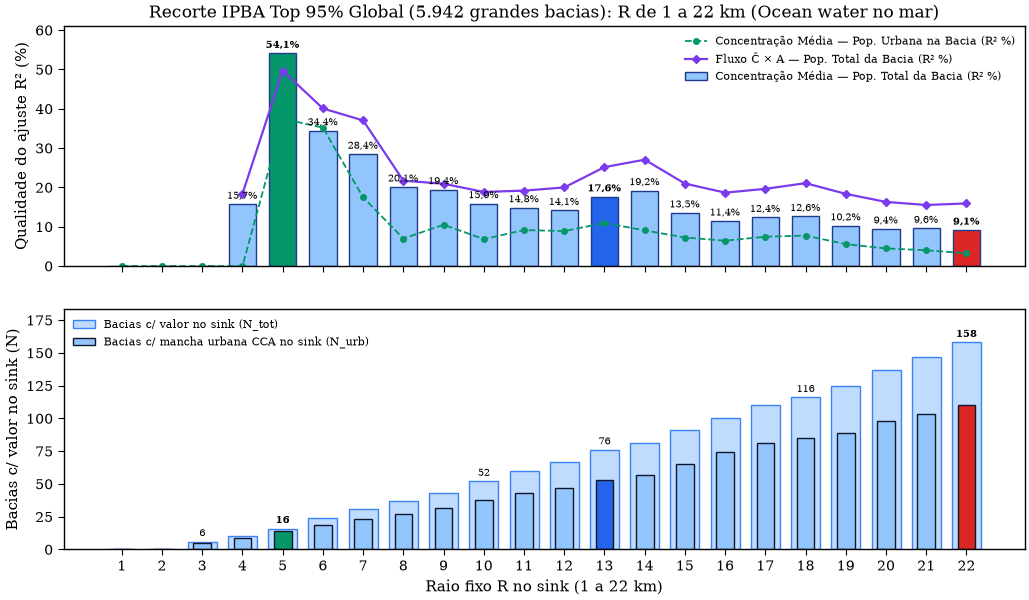

In [4]:
plotar_varredura_r1_a_22km(
    df_varredura,
    titulo="Recorte IPBA Top 95% Global (5.942 grandes bacias): R de 1 a 22 km (Ocean water no mar)",
    min_n=10,
)


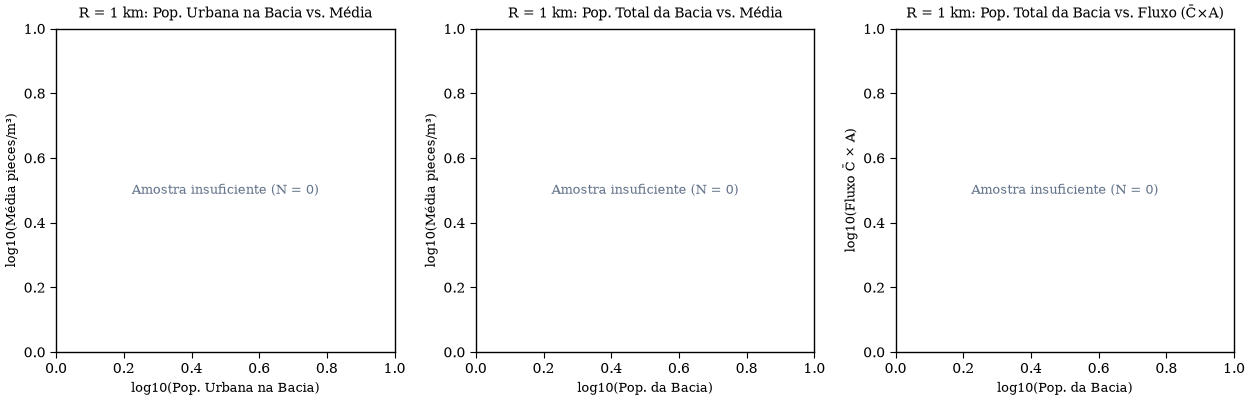

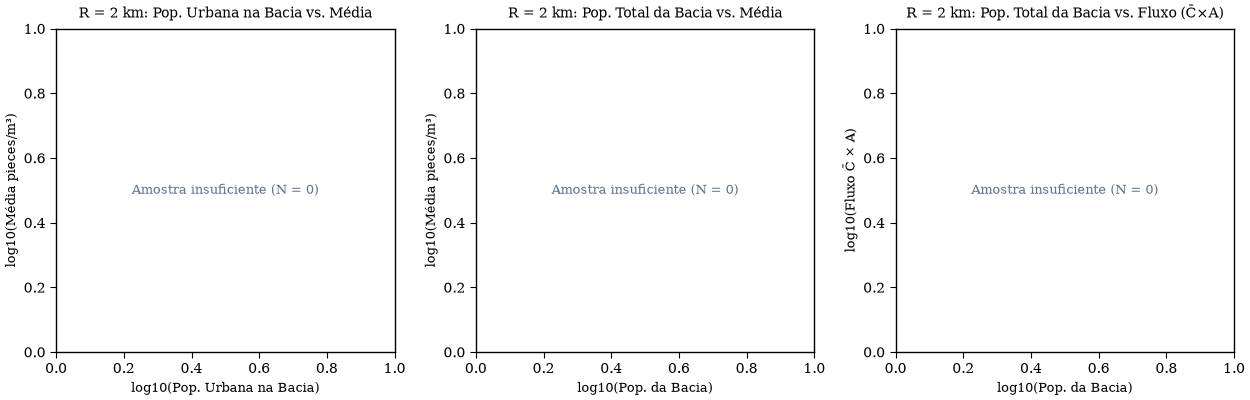

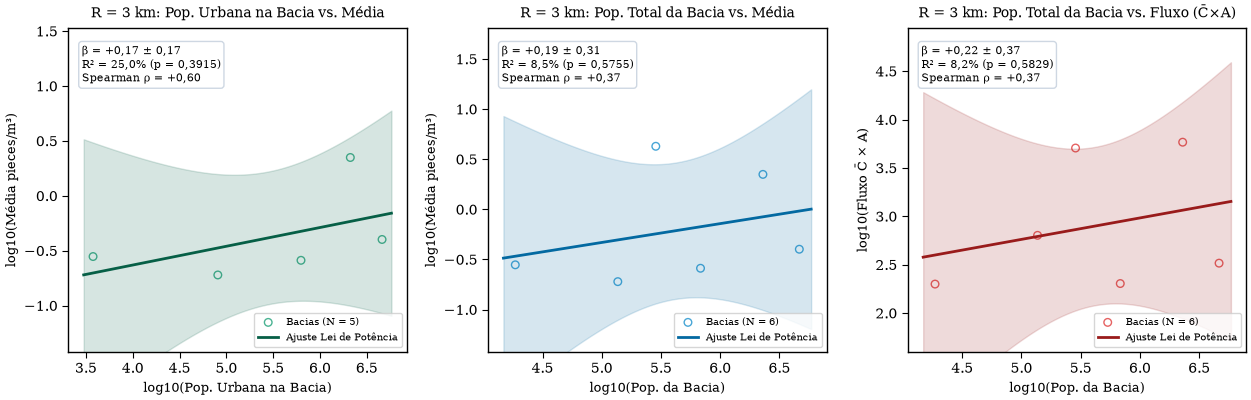

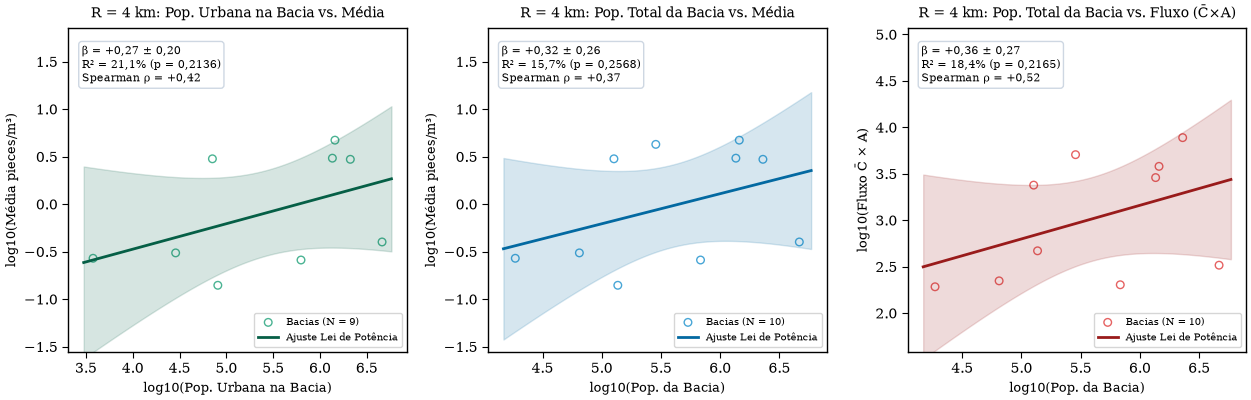

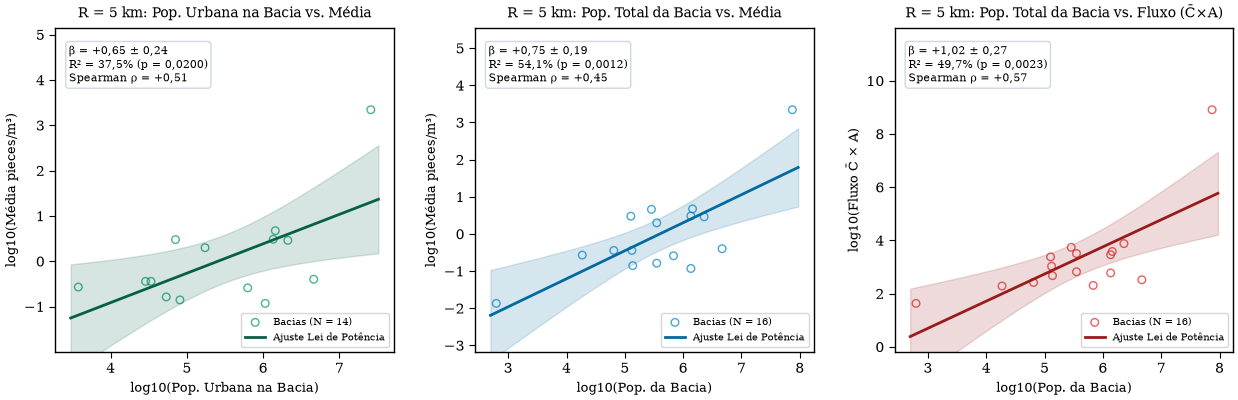

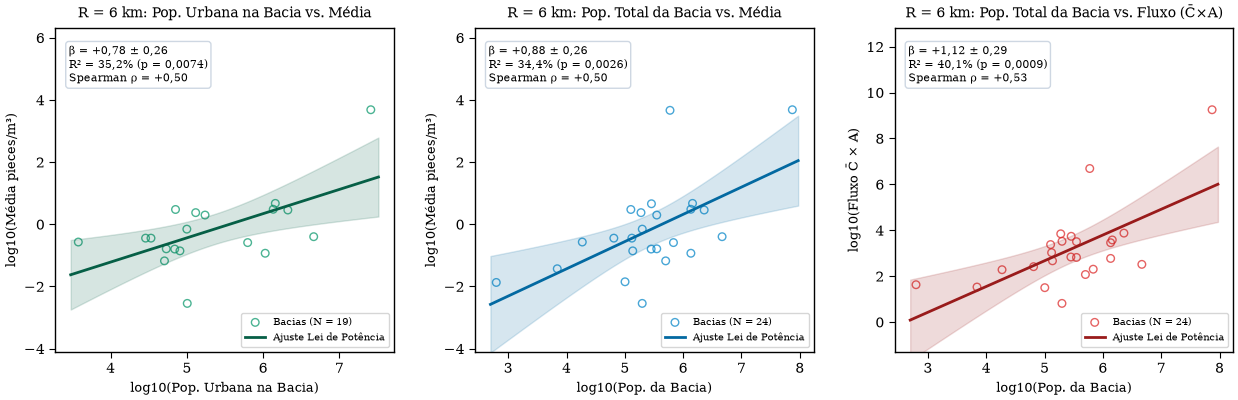

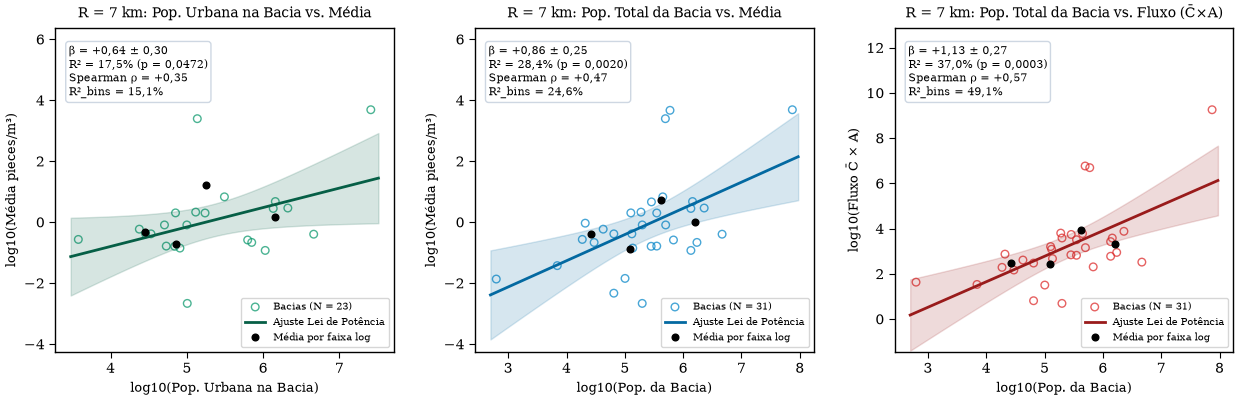

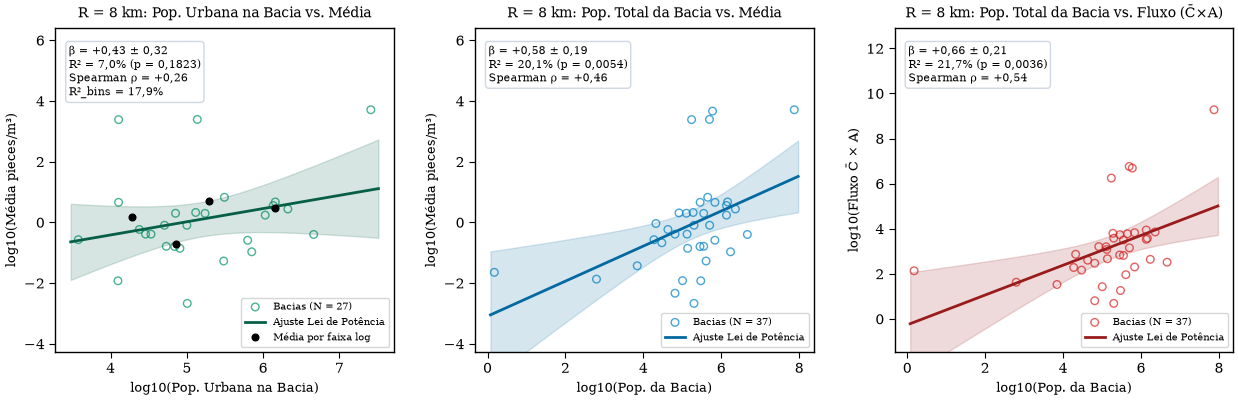

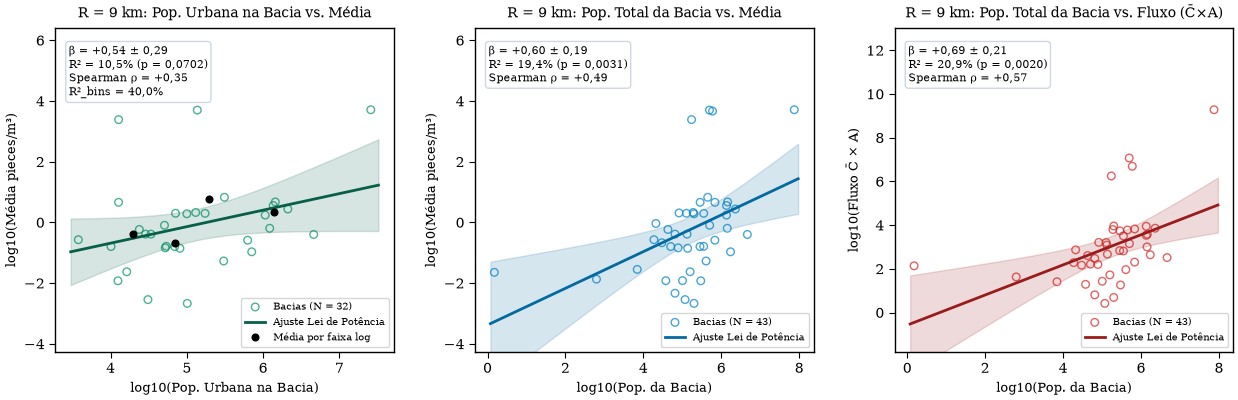

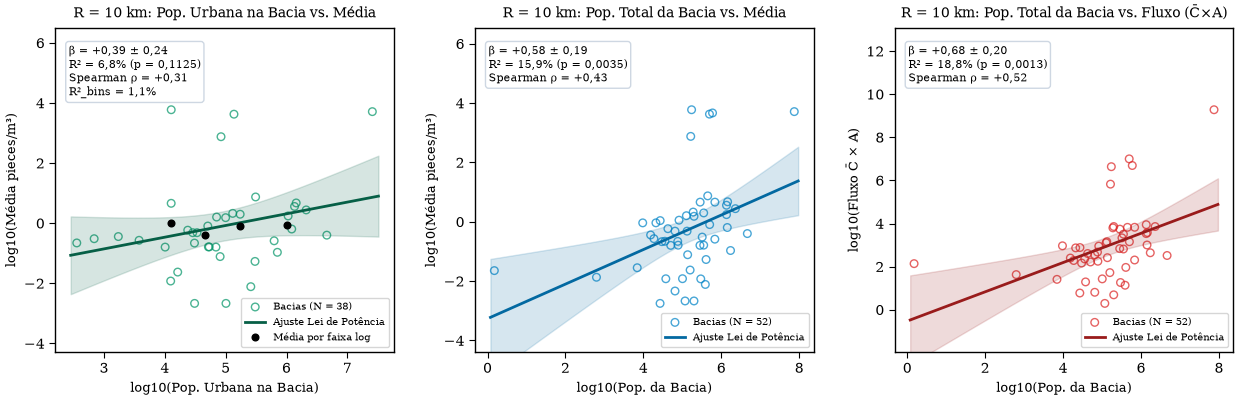

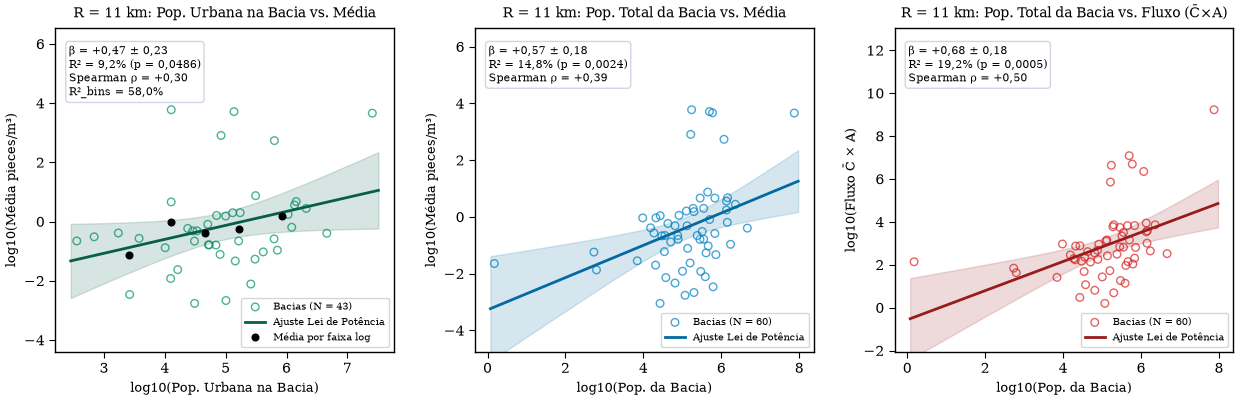

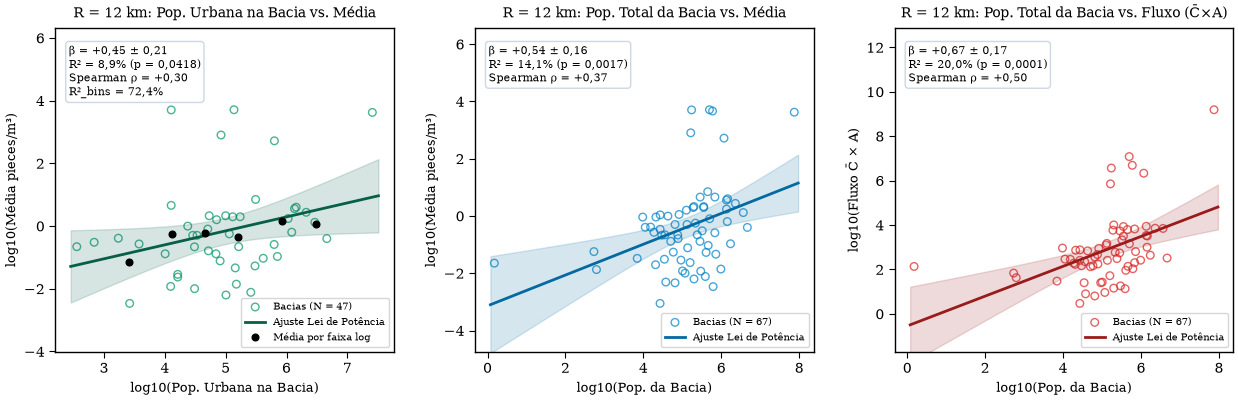

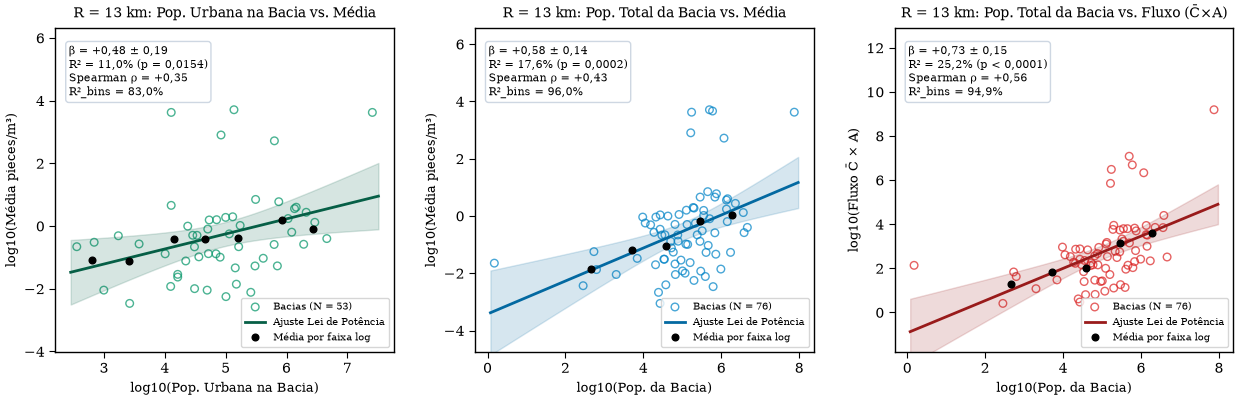

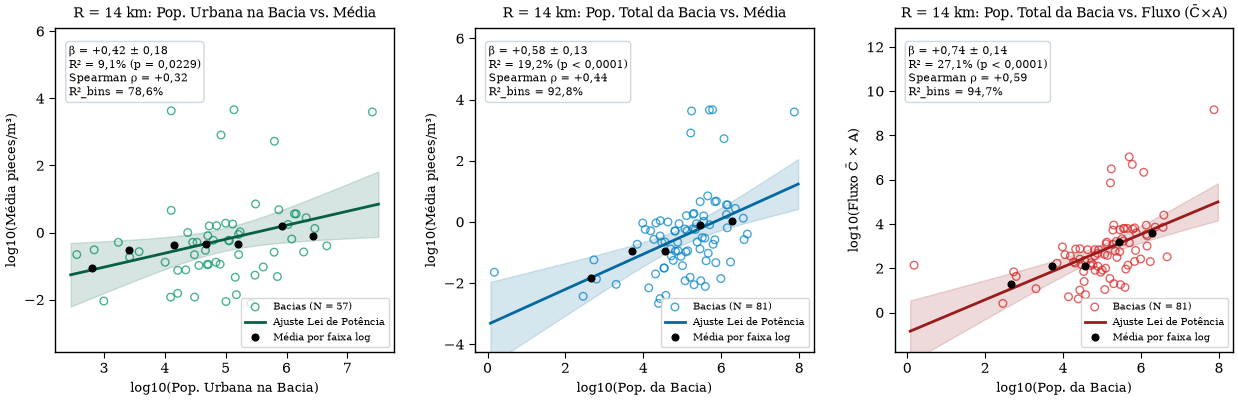

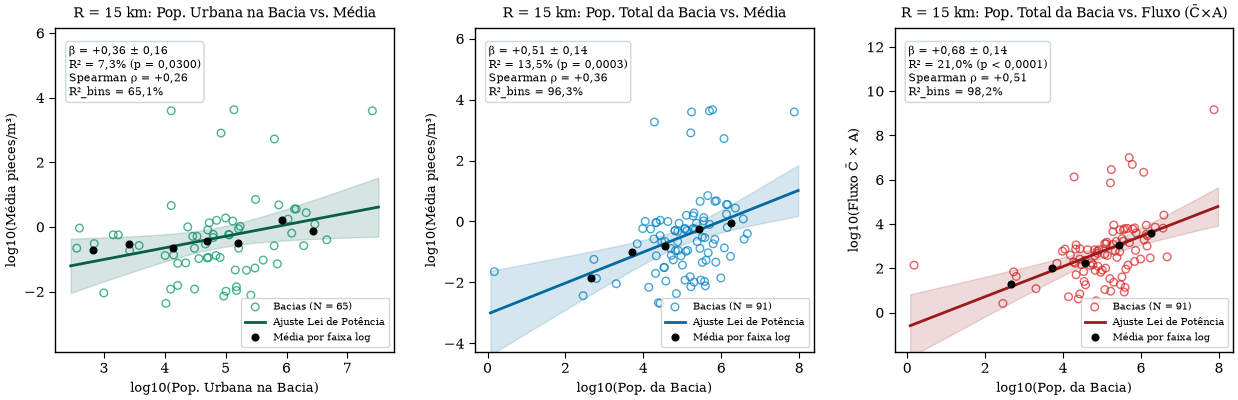

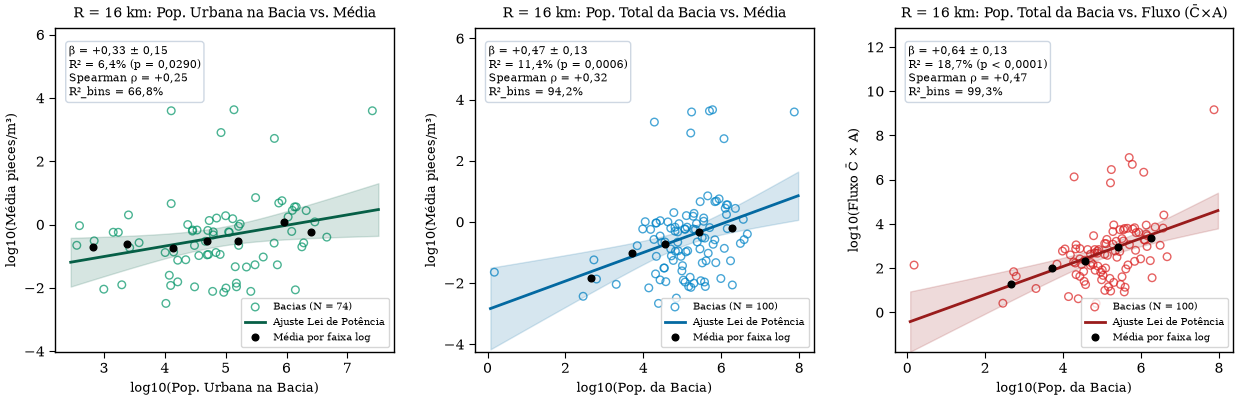

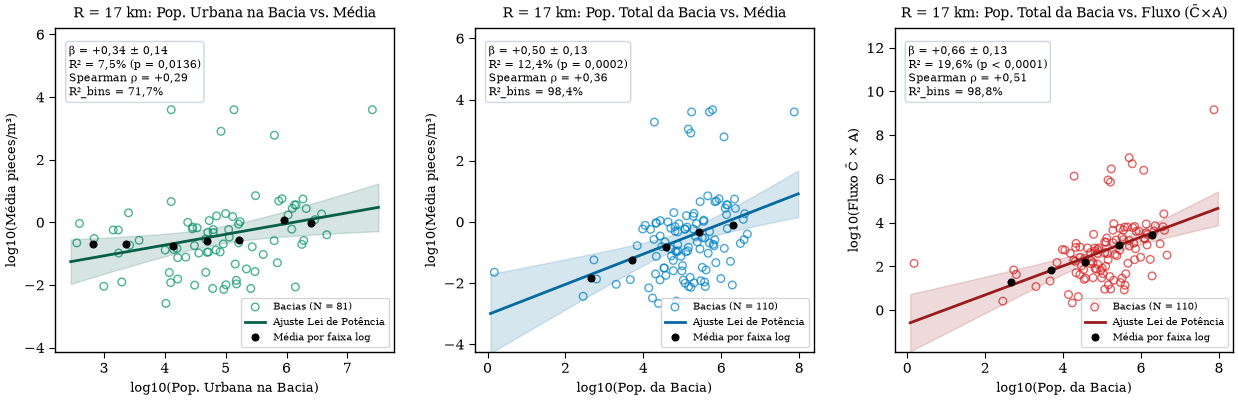

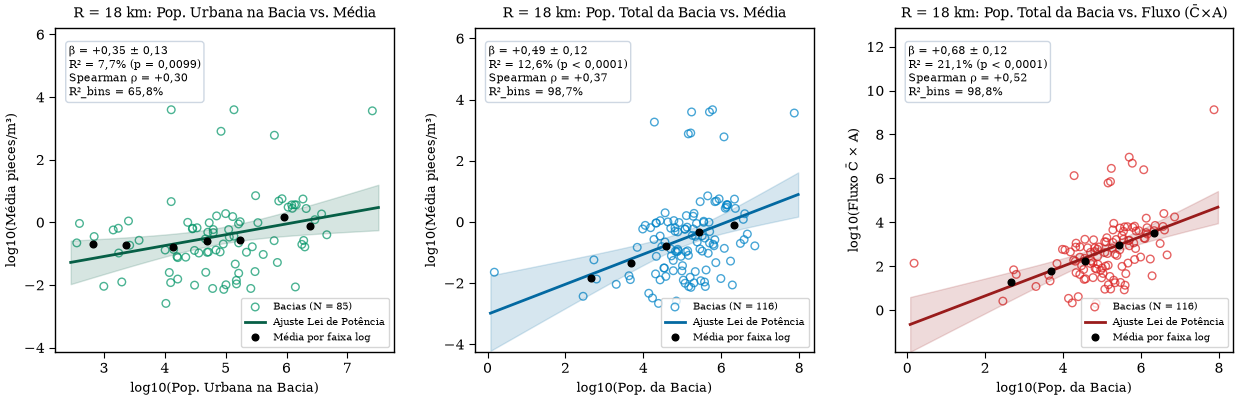

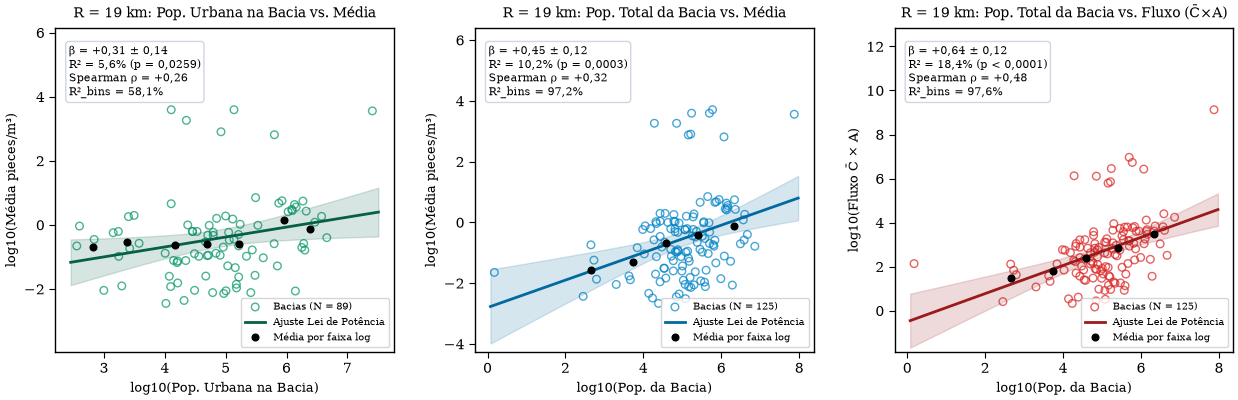

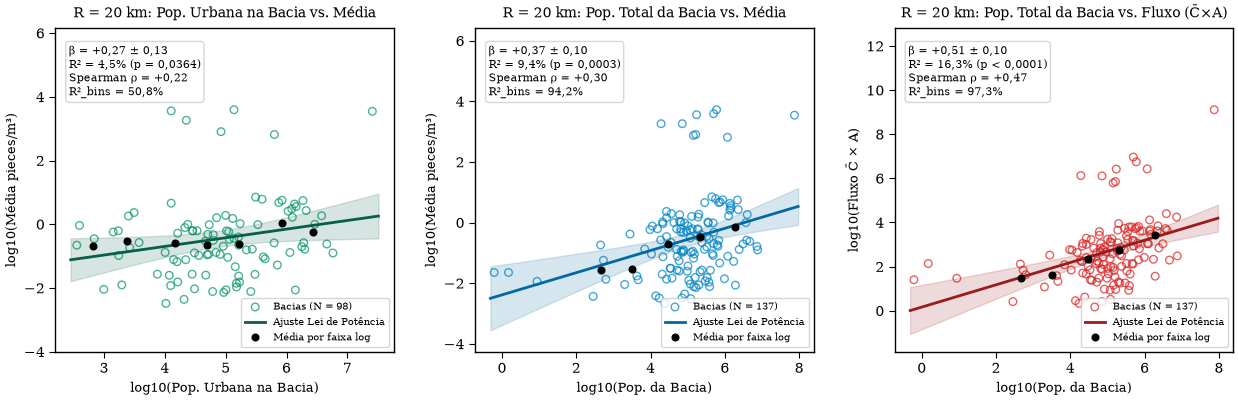

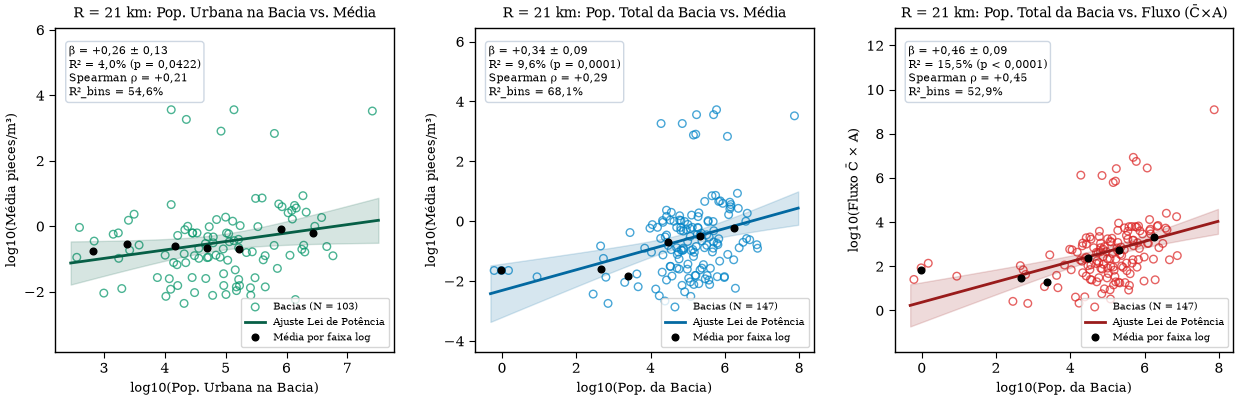

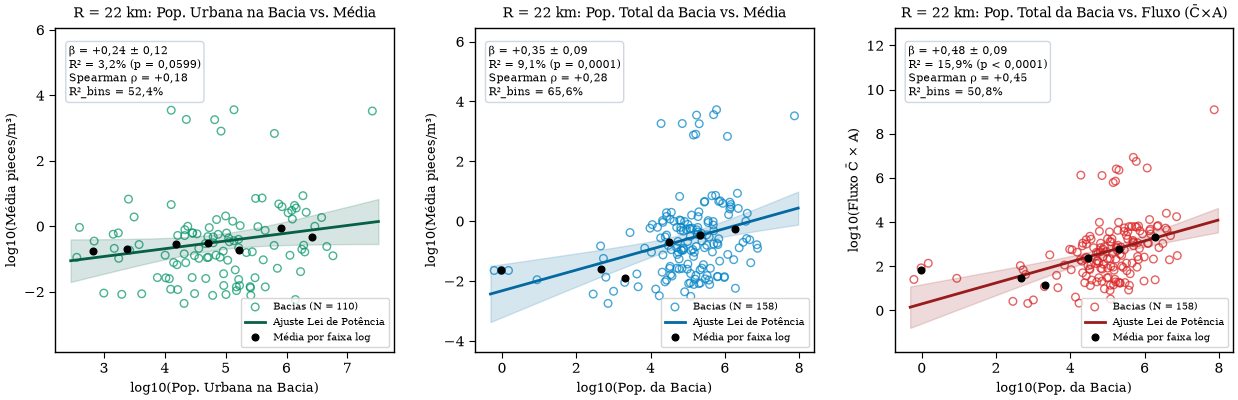

In [5]:
for r_km in range(1, 23):
    df_r = pareados_por_r[r_km]
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.2, 4.2), gridspec_kw={"wspace": 0.24})
    plotar_lei_potencia(ax1, df_r, "urban_population", "mp_mean", f"R = {r_km} km: Pop. Urbana na Bacia vs. Média", "log10(Pop. Urbana na Bacia)", "log10(Média pieces/m³)", "#059669", "#065f46")
    plotar_lei_potencia(ax2, df_r, "total_population", "mp_mean", f"R = {r_km} km: Pop. Total da Bacia vs. Média", "log10(Pop. da Bacia)", "log10(Média pieces/m³)", "#0284c7", "#0369a1")
    plotar_lei_potencia(ax3, df_r, "total_population", "flux", f"R = {r_km} km: Pop. Total da Bacia vs. Fluxo (C̄×A)", "log10(Pop. da Bacia)", "log10(Fluxo C̄ × A)", "#dc2626", "#991b1b")
    plt.show()
